In [10]:
from collections import Counter
import math
import matplotlib.pyplot as plt

In [11]:
ALPHABET = "абвгдежзийклмнопрстуфхцчшщъыьэюя"
K_MAX = 5
LOG_FILE = "entropy_log.txt"

VARIANT_TEXT = ("Мильоны – вас. Нас – тьмы, и тьмы, и тьмы. Попробуйте, сразитесь с нами! "
                "Да, скифы – мы! Да, азиаты – мы, С раскосыми и жадными очами! "
                "Для вас – века, для нас – единый час. Мы, как послушные холопы, "
                "Держали щит меж двух враждебных рас Монголов и Европы!")

In [12]:
def clean_text(text):
    result = ""
    for char in text.lower():
        if char == 'ё':
            char = 'е'
        if char in ALPHABET:
            result += char

    return result

In [13]:
def count_kgrams(text, k):
    grams = [text[i:i + k] for i in range(len(text) - k + 1)]
    return Counter(grams)


def calculate_entropy(text, k):
    counts = count_kgrams(text, k)
    total = sum(counts.values())

    if total == 0:
        return 0.0

    h = 0.0
    for count in counts.values():
        p = count / total
        h -= p * math.log2(p)

    return h

In [14]:
def get_top_letters(text):
    counts = Counter(text)
    total = sum(counts.values())

    sorted_chars = []
    for char, count in counts.most_common():
        freq = count / total if total > 0 else 0
        sorted_chars.append((char, freq))

    return sorted_chars

In [15]:
def write_log(message):
    with open(LOG_FILE, 'a', encoding='utf-8') as f:
        f.write(message + "\n")
    print(message)

In [16]:
def calculate_and_plot(text, name, filename):
    cleaned = clean_text(text)

    write_log(f"\n--- АНАЛИЗ ОТКРЫТОГО ТЕКСТА: {name} ---")
    write_log(f"Очищенный текст: {cleaned}")
    write_log(f"Длина: {len(cleaned)}")

    if len(cleaned) < K_MAX:
        write_log(f"Текст слишком короткий: нужно минимум {K_MAX} букв.")
        return

    top = get_top_letters(cleaned)[:5]
    top_line = ", ".join(f"'{char}': {freq:.4f}" for char, freq in top)
    write_log(f"Топ-5 букв: {top_line}")

    ks = []
    ratios = []

    for k in range(1, K_MAX + 1):
        h = calculate_entropy(cleaned, k)
        ks.append(k)
        ratios.append(h / k)
        write_log(f"k = {k}: H = {h:.4f}, H/{k} = {h / k:.4f}")

    write_log(f"Асимптотическое значение (при k = {ks[-1]}): {ratios[-1]:.4f}")

    plt.figure()
    plt.plot(ks, ratios, marker='o', color='b')
    plt.xlabel('k')
    plt.ylabel('H_k(T)/k')
    plt.title('Зависимость H_k(T)/k от k')
    plt.ylim(bottom=0)
    plt.grid(True)
    plt.xticks(ks)
    plt.savefig(filename)
    plt.show()

    write_log(f"График сохранён в файл {filename}")

In [17]:
def my_variant():
    calculate_and_plot(VARIANT_TEXT, "Вариант 1 (А. Блок, Скифы)", "graph_variant1.png")


def custom_text():
    text = input("Введите текст: ").strip()
    if not text:
        print("Текст пуст.")
        return

    calculate_and_plot(text, "Произвольный текст", "graph_custom.png")


--- АНАЛИЗ ОТКРЫТОГО ТЕКСТА: Вариант 1 (А. Блок, Скифы) ---
Очищенный текст: мильонываснастьмыитьмыитьмыпопробуйтесразитесьснамидаскифымыдаазиатымысраскосымиижаднымиочамидлявасвекадлянасединыйчасмыкакпослушныехолопыдержалищитмеждвухвраждебныхрасмонголовиевропы
Длина: 183
Топ-5 букв: 'а': 0.1038, 'ы': 0.0874, 'и': 0.0820, 'с': 0.0765, 'м': 0.0710
k = 1: H = 4.3776, H/1 = 4.3776
k = 2: H = 6.5971, H/2 = 3.2985
k = 3: H = 7.2374, H/3 = 2.4125
k = 4: H = 7.4099, H/4 = 1.8525
k = 5: H = 7.4279, H/5 = 1.4856
Асимптотическое значение (при k = 5): 1.4856


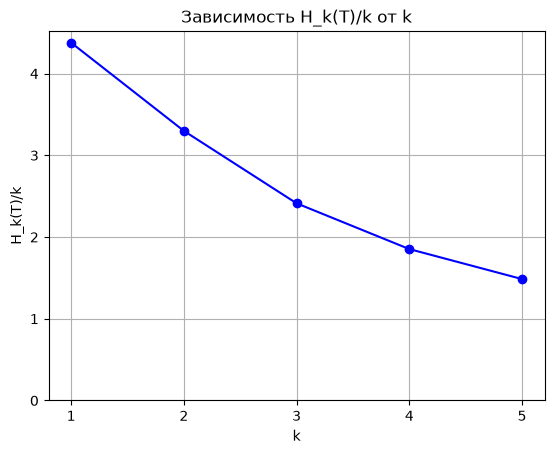

График сохранён в файл graph_variant1.png
--- ВЫХОД ИЗ ПРОГРАММЫ ---
Выход. Все результаты сохранены в entropy_log.txt


In [18]:
def run_menu():
    while True:
        choice = input("\nВыберите пункт меню:\n 1. Вариант 1 (готовый текст)\n 2. Произвольный текст\n 3. Выход\n-> ").strip()

        if choice == '1':
            my_variant()

        elif choice == '2':
            custom_text()

        elif choice == '3':
            write_log("--- ВЫХОД ИЗ ПРОГРАММЫ ---")
            print("Выход. Все результаты сохранены в", LOG_FILE)
            break

        else:
            print("Пожалуйста, выберите 1, 2 или 3.")


run_menu()